# 04 — Honest evaluation & explainability

We evaluate the saved model **once** on the untouched test set, choose the decision
threshold from an explicit business cost, and — the headline — explain predictions
globally and per-applicant with **SHAP**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (8, 4.5)

import json
from src import model as M
from src.explain import CreditExplainer

model = M.load_model()
metrics = json.load(open(config.METRICS_PATH))
df = data.load_raw()
X_train, X_val, X_test, y_train, y_val, y_test = data.split_data(df)
print('Best model:', metrics['best_model'], '| chosen threshold:', round(metrics['threshold'],3))

Best model: xgboost | chosen threshold: 0.19


## Test-set performance (computed once, at the very end)

In [2]:
t = metrics['test']
print(f"ROC-AUC : {t['roc_auc']:.4f}")
print(f"PR-AUC  : {t['pr_auc']:.4f}   (no-skill baseline = {metrics['dataset']['default_rate']:.4f})")
print(f"Brier   : {t['brier']:.4f}   (lower = better calibrated)")
print(f"At threshold {t['threshold']:.2f}:  recall={t['recall']:.3f}  precision={t['precision']:.3f}  F1={t['f1']:.3f}")
print('Confusion matrix:', t['confusion_matrix'])

ROC-AUC : 0.8711
PR-AUC  : 0.4039   (no-skill baseline = 0.0668)
Brier   : 0.0489   (lower = better calibrated)
At threshold 0.19:  recall=0.539  precision=0.378  F1=0.444
Confusion matrix: {'tn': 26214, 'fp': 1781, 'fn': 924, 'tp': 1081}


## The business tradeoff: where to set the threshold

In lending the two errors are not equal. A **false negative** (approve someone who
defaults) loses principal; a **false positive** (reject someone who would have repaid)
loses only the interest margin. We assume a **5:1** cost ratio and pick the threshold
that minimizes expected cost on validation.

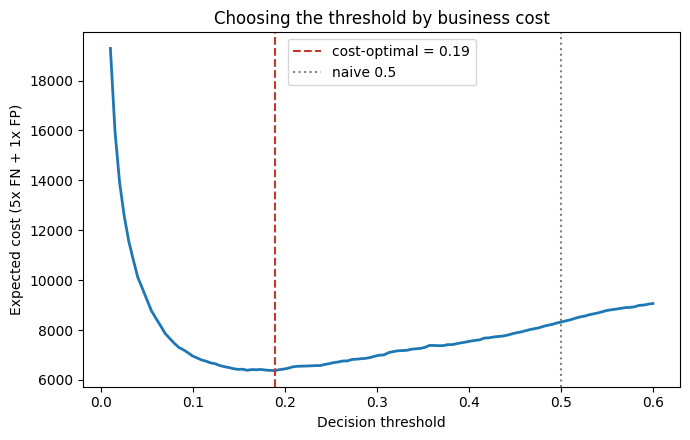

Cost-optimal threshold 0.19 catches far more defaulters than the naive 0.5.


In [3]:
prob_val = model.predict_proba(X_val)[:,1]
ths = np.linspace(0.01,0.6,120)
costs = []
yv = y_val.values
for th in ths:
    pred = (prob_val>=th).astype(int)
    fp = int(((pred==1)&(yv==0)).sum()); fn = int(((pred==0)&(yv==1)).sum())
    costs.append(config.COST_FALSE_POSITIVE*fp + config.COST_FALSE_NEGATIVE*fn)
best = ths[int(np.argmin(costs))]
fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(ths, costs, lw=2)
ax.axvline(best, color='#c0392b', ls='--', label=f'cost-optimal = {best:.2f}')
ax.axvline(0.5, color='grey', ls=':', label='naive 0.5')
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Expected cost (5x FN + 1x FP)')
ax.set_title('Choosing the threshold by business cost'); ax.legend(); plt.tight_layout(); plt.show()
print(f'Cost-optimal threshold {best:.2f} catches far more defaulters than the naive 0.5.')

**Read:** the cost-optimal threshold sits well below 0.5 — we
deliberately accept more false positives (rejected good applicants) to avoid the much
costlier false negatives (approved defaulters). This is the honest, business-aware
answer, not a single accuracy number.

## Explainability — the headline

### Global: what drives the model overall

In [4]:
explainer = CreditExplainer(model)
Xs = X_test.sample(2000, random_state=config.RANDOM_STATE)
imp = explainer.global_importance(Xs)
print(imp.head(8).to_string(index=False))

                             feature  mean_abs_shap
RevolvingUtilizationOfUnsecuredLines       0.754580
                        TotalPastDue       0.738647
                                 age       0.219345
     NumberOfOpenCreditLinesAndLoans       0.179876
                           DebtRatio       0.134065
             NumberOfTimes90DaysLate       0.103101
        NumberRealEstateLoansOrLines       0.085348
                  IncomePerDependent       0.070732


The pre-rendered SHAP beeswarm (from `src.train`) shows direction as well as magnitude:

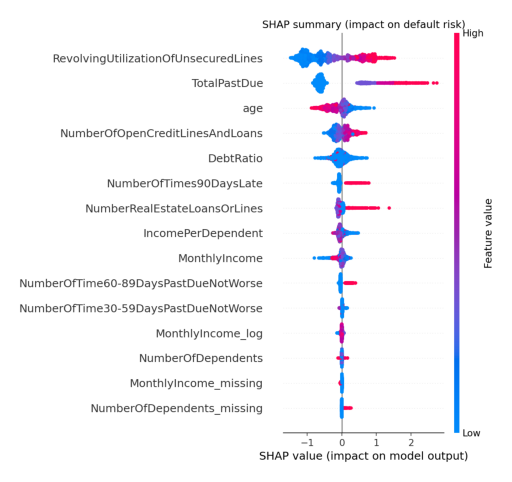

In [5]:
from matplotlib import image as mpimg
for fname in ['shap_global_beeswarm.png']:
    p = config.FIGURES / fname
    if p.exists():
        plt.figure(figsize=(8,6)); plt.imshow(mpimg.imread(p)); plt.axis('off'); plt.show()

### Local: *why this applicant?*  (per-prediction explanation)

In [6]:
prob_test = model.predict_proba(X_test)[:,1]
hi = int(np.argmax(prob_test))
exp = explainer.explain_one(X_test.iloc[[hi]])
print(f'Highest-risk applicant: predicted default prob = {prob_test[hi]:.3f}')
print('Top contributions (log-odds; + raises risk, - lowers):')
for c_ in exp['contributions'][:6]:
    print(f"  {c_['label']:28s} value={c_['value']:>8.2f}  shap={c_['shap_value']:+.3f}")

Highest-risk applicant: predicted default prob = 0.924
Top contributions (log-odds; + raises risk, - lowers):
  Total past-due events        value=   16.00  shap=+2.584
  Credit utilization ratio     value=    0.95  shap=+0.828
  Times 90+ days late          value=    5.00  shap=+0.654
  Open credit lines & loans    value=   23.00  shap=+0.547
  Debt ratio                   value=    0.67  shap=+0.262
  Times 60-89 days late        value=    2.00  shap=+0.261


This per-prediction breakdown is exactly what the API returns and the
dashboard visualizes — turning a black-box score into an auditable decision.

## Fairness & limitations (honest)

- **No protected attributes** are in this dataset (no race/gender/ethnicity), so we
  can't directly audit demographic fairness. But features like income and age can act
  as **proxies**; a real deployment would require disparate-impact testing on
  protected groups.
- **Calibration is good but not perfect** (see `calibration.png`); probabilities
  should be monitored and periodically re-calibrated in production.
- **This is a portfolio model, not an underwriting system.** It ignores regulatory
  requirements (adverse-action notices, ECOA/FCRA), temporal drift, and the feedback
  loop where rejected applicants never reveal their true outcome.
- **The 5:1 cost ratio is an assumption**, not a measured business value — the
  threshold should be set from real expected loss vs. margin.

## Takeaway
A gradient-boosted model reaches **ROC-AUC ≈ 0.87** with **calibrated probabilities**,
and — crucially — every prediction is **explainable** down to the feature level, which
is what makes a credit model auditable and trustworthy.